Cree un nuevo proyecto (Parcial_fundamentos) en el cual hice un documento de jupyter notebook (analisis_parcial_fundamentos.ipynb) para poder ir documentando lo que iba sucediendo. 

Ahora, siguiendo los mismos pasos que ya habia seguido en las clases cuando abria un nuevo proyecto, cree una carpeta (.venv) en donde instalé todas las herramientas que iba a usar, es decir: pandas, seaborn, matplotlib. Pandas para manejar tablas y datos, Matplotlib y Seaborn para hacer los gráficos. 

A este paso a paso que ya tenia establecido, añadí un paso, recomendado por la IA Claude. Debido a que no iba a usar documentos .py (python) como venia usando, sino un .ipynb (jupyter notebook), debido a que queria tener las anotaciones y el codigo en el mismo archivo, era necesario instalar Ipykernel para poder ejecutar los codigos del cuaderno 

Esta instalación la realicé desde la terminal

<img src="Evidencias/Terminal_1.jpg" width="600">

No salio ningun error, todo quedó bien instalado 

Hice la elección de la siguiente base de datos, Gobernación de Sucre. (2025). Inventario Otras especies en el departamento de Sucre [Conjunto de datos]. Portal de Datos Abiertos de Colombia, datos.gov.co. Licencia CC BY-SA. https://www.datos.gov.co/Ambiente-y-Desarrollo-Sostenible/Inventario-Otras-especies-en-el-departamento-de-Su/33bv-k4eh/about_data Descargado el 21 de noviembre de 2026.

Elegí este conjunto porque, con lo que se ve en la página del portal antes de descargarlo, cumple los criterios del enunciado:

- **Repositorio público con licencia declarada:** datos.gov.co, publicado por la Gobernación de Sucre, licencia CC BY-SA.
- **Más de 200 filas y 8 columnas:** 622 filas y 10 columnas.
- **Variables numéricas y categóricas:** cantidades por especie (Equinos, Asnos, Mulos, Bufalos, Ovinos, Caprinos y Total) y variables de texto (Municipio y Subregión), además del año.
- **Imperfecciones reales:** en la vista de datos se ven valores vacíos ("null") en algunas columnas.
- **No es un conjunto de tutorial:** es un inventario pecuario de un departamento colombiano.
- **Tema cercano a las ciencias biológicas:** poblaciones de animales de producción y su distribución en el territorio.

<img src="Evidencias/base_de_datos.jpg" width="600">

Ahora con pandas analizaré el estado del conjunto 

Primero importo las herramientas instaladas 

In [270]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns 

Ahora, cargo el archivo de los datos y visualizo las primeras lineas de la tabla y ademas guardo la cantidad de filas antes de comenzar con la limpieza 

In [271]:
df_datos = pd.read_csv("Datos/Inventario_Otras_especies_en_el_departamento_de_Sucre_20261121.csv")
filas_antes = len(df_datos)
print("Filas antes de limpiar:", filas_antes)
df_datos

Filas antes de limpiar: 622


,Año,Municipio,Subregión,Equinos,Asnos,Mulos,Bufalos,Ovinos,Caprinos,Total
0,"2,001",Sincelejo,Montes de María,"1,836.00","1,836.00",243.00,NaN,743.00,NaN,"4,658.00"
1,"2,001",Buenavista,Sabanas,"1,835.00",455.00,308.00,NaN,"1,062.00",20.00,"3,680.00"
2,"2,001",Caimito,San Jorge,840.00,110.00,140.00,NaN,"1,450.00",450.00,"2,990.00"
3,"2,001",Colosó,Montes de María,873.00,"1,492.00",82.00,NaN,"1,300.00",48.00,"3,795.00"
4,"2,001",Corozal,Sabanas,"2,620.00","1,650.00",85.00,NaN,"1,253.00",40.00,"5,648.00"
...,...,...,...,...,...,...,...,...,...,...
617,"2,025",San Pedro,Sabanas,"2,841.00",NaN,NaN,45.00,"1,434.00",481.00,"4,801.00"
618,"2,025",Santiago de Tolú,Morrosquillo,"1,206.00",NaN,NaN,"2,442.00","1,023.00",174.00,"4,845.00"
619,"2,025",Sincelejo,Montes de María,"1,284.00",NaN,NaN,216.00,577.00,"1,054.00","3,131.00"
620,"2,025",Sucre,Mojana,"2,032.00",NaN,NaN,"3,267.00",109.00,89.00,"5,497.00"


Comienzo con el diagnóstico de los datos
Sumo a cada columna 1, para ver si los datos estan en texto o en numero (solo lo hago con las columnas que son numeros) 
<img src="Evidencias/Error_por_tipo_de_datos_1.jpg" width="300">
<img src="Evidencias/Error_por_tipo_de_datos.jpg" width="600">

El error dice: "can only concatenate str (not "int") to str" al intentar esto con las siguientes columnas: Año, Equinos, Asnos, Mulos, Bufalos, Ovinos, Caprinos y Total. Por lo tanto se debe cambiar a datos numericos.

Como los valores son cantidad de animales, espero que sean numeros enteros, por lo tanto los convierto a float y luego a int como se vio en clase. 

Aca me apareció el siguiente error 

<img src="Evidencias/Falla_en_numeros_enteros.jpg" width="600">

Este error me dice que no puedo convertir a int las celdas NA o inf, por esto, voy a resolver las celdas vacias primero, pasando todo a float, no a int.

Y posterior, resto la cantidad de datos que sean numeros mayores a 0 al total de datos que tiene cada columna. Para saber cuantos datos se deben eliminar.

In [272]:
especies = ['Equinos', 'Asnos', 'Mulos', 'Bufalos', 'Ovinos', 'Caprinos']
columnas_numericas = ['Año'] + especies + ['Total']

for col in columnas_numericas:
    df_datos[col] = df_datos[col].astype(str).str.replace(',', '', regex=False).astype(float)

filas_antes = len(df_datos)
print("Filas antes de limpiar:", filas_antes)

for col in columnas_numericas:
    print(col, "vacíos:", filas_antes - len(df_datos[df_datos[col] >= 0]))

Filas antes de limpiar: 622
Año vacíos: 0
Equinos vacíos: 2
Asnos vacíos: 191
Mulos vacíos: 188
Bufalos vacíos: 246
Ovinos vacíos: 15
Caprinos vacíos: 181
Total vacíos: 2


Al revisar los vacíos de cada columna, vi que hay muchas celdas vacías. Si eliminaba las filas que tenían algún vacío, iba a perder mucha información. Por eso le pregunté a la IA qué podía hacer para no perder tantas filas. Me recomendó llenar las celdas vacías con ceros usando `fillna(0)`, que reemplaza cada celda vacía por 0, y después, al graficar, excluir esos ceros con la condición "mayor que 0" para que no afecten las gráficas. Creo que un vacío significa que ese año no hubo registro y no que no hubiera animales.

Antes de hacer el cambio comprobé que ninguna columna tenía ceros reales, para no confundir los ceros que agrego con los que ya existían.

También paso los datos a números enteros, porque ya no quedarán vacíos. La IA además me propuso `dtypes`, una línea de código que me dice el tipo de dato de cada columna.

In [273]:
for col in columnas_numericas:
    print(col, "ceros reales:", len(df_datos[df_datos[col] == 0]))

df_datos = df_datos.fillna(0)

for col in columnas_numericas:
    df_datos[col] = df_datos[col].astype(int)

df_datos.dtypes

Año ceros reales: 0
Equinos ceros reales: 0
Asnos ceros reales: 0
Mulos ceros reales: 0
Bufalos ceros reales: 0
Ovinos ceros reales: 0
Caprinos ceros reales: 0
Total ceros reales: 0


Año          int64
Municipio      str
Subregión      str
Equinos      int64
Asnos        int64
Mulos        int64
Bufalos      int64
Ovinos       int64
Caprinos     int64
Total        int64
dtype: object

Solo por confirmar, ahora vuelvo a hacer conteo de ceros, despues del cambio y me deberia dar como resultado la misma cantidad de celdas vacias que tenia cada columna

In [274]:
for col in columnas_numericas:
    print(col, "ceros reales:", len(df_datos[df_datos[col] == 0]))

Año ceros reales: 0
Equinos ceros reales: 2
Asnos ceros reales: 191
Mulos ceros reales: 188
Bufalos ceros reales: 246
Ovinos ceros reales: 15
Caprinos ceros reales: 181
Total ceros reales: 2


Efectivamente, son iguales, ya no hay vacios.

Antes de revisar los datos quise saber cuántos municipios debería tener el conjunto de datos. Busqué fuentes sobre el departamento de Sucre:

1. Ministerio de Comercio, Industria y Turismo (2024). *Perfil económico: Departamento de Sucre*. Indica que el departamento tiene 26 municipios. https://www.mincit.gov.co/getattachment/de055b12-9d7b-4673-8cdd-97cf488dbd54/Sucre.aspx
2. Secretaría de Educación Departamental de Sucre (2012). *Plan de formación de docentes y directivos docentes, Departamento de Sucre 2012-2015*. Sección 1.4: lista los 26 municipios y su composición por subregión. https://www.mineducacion.gov.co/1759/articles-319469_archivo_pdf_Sucre.pdf

Con esas fuentes escribí la lista de 26 municipios esperados antes de mirar los datos, y la comparé con los municipios que aparecen en el conjunto. Yo esperaría que en el conjunto se encuentren los 26 municipios sin años repetidos. Para esto la IA me propuso usar unique que devuelve los valores de una columna sin repetirlos. Después cuento esa lista con `len()`.

In [275]:
municipios_esperados = [ 'Sincelejo', 'Buenavista', 'Caimito', 'Colosó', 'Corozal', 'Coveñas',
    'Chalán', 'El Roble', 'Galeras', 'Guaranda', 'La Unión', 'Los Palmitos',
    'Majagual', 'Morroa', 'Ovejas', 'San Antonio de Palmito', 'Sampués',
    'San Benito Abad', 'San Juan de Betulia', 'San Marcos', 'San Onofre',
    'San Pedro', 'San Luis de Sincé', 'Sucre', 'Santiago de Tolú', 'Toluviejo']
subregiones_esperadas = ['San Jorge', 'Mojana', 'Montes de María', 'Sabanas', 'Morrosquillo']
print("Municipios esperados:", len(municipios_esperados))
print("Subregiones esperadas:", len(subregiones_esperadas))

municipios_en_datos = df_datos['Municipio'].unique()
subregiones_en_datos = df_datos['Subregión'].unique()
print("Municipios en los datos:", len(municipios_en_datos))
print("Subregiones en los datos:", len(subregiones_en_datos))

Municipios esperados: 26
Subregiones esperadas: 5
Municipios en los datos: 27
Subregiones en los datos: 6


Al contar los nombres distintos obtuve 27 municipios y 6 subregiones, pero la literatura indica 26 municipios y 5 subregiones. Es decir, hay un municipio y una subregión de más. Con los conteos no sé cuáles son, ni si además falta alguno de los esperados, porque un municipio podría faltar y otros dos sobrar y el total daría igual.

Para averiguarlo comparo las listas nombre por nombre. Uso `isin`, que pregunta fila por fila si un valor está dentro de una lista y responde verdadero o falso, y con "== False" me quedo solo con los que no están. Lo hago en los dos sentidos: primero, qué municipios y subregiones esperados no aparecen en los datos (para ver si falta alguno), y segundo, qué valores hay en los datos que no estaban en la lista esperada (para identificar los sobrantes).

Espero que no falte ningún municipio ni subregión, y que sobre un valor en cada columna.

In [276]:
tabla_municipios_esperados = pd.DataFrame({'Municipio': municipios_esperados})
tabla_subregiones_esperadas = pd.DataFrame({'Subregión': subregiones_esperadas})

print("Municipios esperados que NO están en los datos:")
print(tabla_municipios_esperados[tabla_municipios_esperados['Municipio'].isin(df_datos['Municipio']) == False])

print("Municipios en los datos que NO eran esperados:")
print(df_datos[df_datos['Municipio'].isin(municipios_esperados) == False]['Municipio'].unique())

print("Subregiones esperadas que NO están en los datos:")
print(tabla_subregiones_esperadas[tabla_subregiones_esperadas['Subregión'].isin(df_datos['Subregión']) == False])

print("Subregiones en los datos que NO eran esperadas:")
print(df_datos[df_datos['Subregión'].isin(subregiones_esperadas) == False]['Subregión'].unique())

Municipios esperados que NO están en los datos:
Empty DataFrame
Columns: [Municipio]
Index: []
Municipios en los datos que NO eran esperados:
<StringArray>
['No existen datos']
Length: 1, dtype: str
Subregiones esperadas que NO están en los datos:
Empty DataFrame
Columns: [Subregión]
Index: []
Subregiones en los datos que NO eran esperadas:
<StringArray>
['No existen datos']
Length: 1, dtype: str


Como se puede observar, aparece que no faltan municipios, solo sobra una fila de "No existen datos" tanto en subregion como en municipio. le voy a dar un vistazo a estas filas para ver si brindan información relevante o pueden ser descartadas 

In [277]:
df_datos[df_datos['Municipio'] == 'No existen datos']
df_datos[df_datos['Subregión'] == 'No existen datos']

,Año,Municipio,Subregión,Equinos,Asnos,Mulos,Bufalos,Ovinos,Caprinos,Total
128,2006,No existen datos,No existen datos,0,0,0,0,0,0,0


Observando esta fila, determino que no me aporta información y por lo tanto la voy a descartar. Quiero comprobar si hay mas datos del año 2006

In [278]:
df_datos[df_datos['Año'] == 2006]

,Año,Municipio,Subregión,Equinos,Asnos,Mulos,Bufalos,Ovinos,Caprinos,Total
128,2006,No existen datos,No existen datos,0,0,0,0,0,0,0


Con esta informacion determino que simplemente no habra datos reportados en el año 2006. Y la voy a eliminar. Y confirmar que me quedaron 26 municipios y 5 subregiones que son lo esperado

In [279]:
df_datos = df_datos[df_datos['Municipio'].isin(['No existen datos']) == False]
print("Antes:", filas_antes, "| Después:", len(df_datos))
print(df_datos['Año'].unique())

print("Municipios distintos:", len(df_datos['Municipio'].unique()))
print("Subregiones distintas:", len(df_datos['Subregión'].unique()))

Antes: 622 | Después: 621
[2001 2002 2003 2004 2005 2007 2008 2009 2010 2011 2012 2013 2014 2015
 2016 2017 2018 2019 2020 2021 2022 2023 2024 2025]
Municipios distintos: 26
Subregiones distintas: 5


Ya con esta fila eliminada, el conjunto quedó con 621 filas, 26 municipios y 5 subregiones, que coincide con lo esperado según la literatura. 

El conjunto cubre los años de 2001 a 2025, que son 25 años. La fila "No existen datos" era el único registro de 2006 y la eliminé, así que ese año ya no está y quedan 24 años.

Ahora reviso dos cosas con mis propios datos: si algún municipio tiene un año repetido, y si a algún municipio le faltan años. Espero que no haya años repetidos. Como cada municipio debería tener un registro por año, espero que todos tengan los mismos años, pero no sé si es así.

In [280]:
for m in df_datos['Municipio'].unique():
    sub = df_datos[df_datos['Municipio'] == m]
    filas = len(sub)
    años_distintos = len(sub['Año'].unique())
    if filas > años_distintos:
        print(m, "tiene", filas, "filas pero solo", años_distintos, "años distintos")

print("Revisión terminada")

Revisión terminada


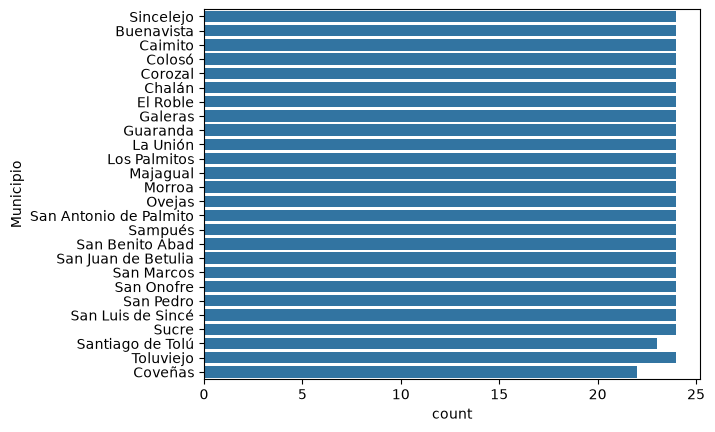

In [281]:
sns.countplot(data=df_datos, y='Municipio')
plt.show()

Como cada municipio debería tener una fila por año, esperaba 24 filas por municipio, es decir, 624 filas en total (26 municipios × 24 años).

Comparé lo esperado con lo que hay: 24 municipios tienen las 24 filas, pero Coveñas tiene 22 y Santiago de Tolú 23, así que faltan 3 registros (621 de 624).

Todavía no sé cuáles son esos registros. A continuación los reviso: recorro cada municipio y cada año de la lista esperada, y muestro los que no aparecen.

In [282]:
años_esperados = [2001, 2002, 2003, 2004, 2005, 2007, 2008, 2009, 2010, 2011, 2012, 2013,
                   2014, 2015, 2016, 2017, 2018, 2019, 2020, 2021, 2022, 2023, 2024, 2025]

for m in municipios_esperados:
    sub = df_datos[df_datos['Municipio'] == m]
    for a in años_esperados:
        n = len(sub[sub['Año'] == a])
        if n < 1:
            print(m, a, "falta")

print("Revisión terminada")

Coveñas 2001 falta
Coveñas 2002 falta
Santiago de Tolú 2024 falta
Revisión terminada


La revisión mostró exactamente tres registros faltantes: Coveñas en 2001 y 2002, y Santiago de Tolú en 2024. Esto cuadra con el conteo anterior (22 y 23 filas) y completa la cuenta de 621 de 624 registros esperados.

Ahora, para cerrar el diagnóstico hago tres comprobaciones, cada una con una pregunta distinta:

1. **¿Hay inventarios negativos?** Una cantidad de animales no puede ser negativa. Para cada columna numérica cuento las filas con valores menores que 0.
2. **¿Hay años que no existen?** Cuento las filas cuyo año no está en la lista de años esperados (2001 a 2025, sin 2006), usando `isin` con "== False", como antes.
3. **¿La columna Total coincide con la suma de las especies?** 
La IA me sugiere que sumando, fila por fila, Equinos, Asnos, Mulos, Bufalos, Ovinos y Caprinos, puedo determinar si la columna "Total" si coincide con la suma de las celdas correspondientes a cada año. 

Espero que las tres den 0.

In [283]:
for col in columnas_numericas:
    print(col, "negativos:", len(df_datos[df_datos[col] < 0]))

print("Filas con un año fuera de la lista:", len(df_datos[df_datos['Año'].isin(años_esperados) == False]))

suma = (df_datos['Equinos'] + df_datos['Asnos'] + df_datos['Mulos']
        + df_datos['Bufalos'] + df_datos['Ovinos'] + df_datos['Caprinos'])
print("Filas donde Total no coincide con la suma de las especies:", len(df_datos[(suma == df_datos['Total']) == False]))

Año negativos: 0
Equinos negativos: 0
Asnos negativos: 0
Mulos negativos: 0
Bufalos negativos: 0
Ovinos negativos: 0
Caprinos negativos: 0
Total negativos: 0
Filas con un año fuera de la lista: 0
Filas donde Total no coincide con la suma de las especies: 0


Las tres comprobaciones dieron 0. Ninguna columna numérica tiene valores negativos, ninguna fila tiene un año fuera de la lista esperada, y la columna Total coincide con la suma de las seis especies en las 621 filas.

Ahora, normalizo los nombres de las columnas para que sean más fáciles de escribir: los paso a minúsculas y quito las tildes. Dejo la ñ en "año", como se hizo en clase.

In [284]:
df_datos = df_datos.rename(columns={'Año': 'año',
                                    'Municipio': 'municipio',
                                    'Subregión': 'subregion',
                                    'Equinos': 'equinos',
                                    'Asnos': 'asnos',
                                    'Mulos': 'mulos',
                                    'Bufalos': 'bufalos',
                                    'Ovinos': 'ovinos',
                                    'Caprinos': 'caprinos',
                                    'Total': 'total'})

df_datos

,año,municipio,subregion,equinos,asnos,mulos,bufalos,ovinos,caprinos,total
0,2001,Sincelejo,Montes de María,1836,1836,243,0,743,0,4658
1,2001,Buenavista,Sabanas,1835,455,308,0,1062,20,3680
2,2001,Caimito,San Jorge,840,110,140,0,1450,450,2990
3,2001,Colosó,Montes de María,873,1492,82,0,1300,48,3795
4,2001,Corozal,Sabanas,2620,1650,85,0,1253,40,5648
...,...,...,...,...,...,...,...,...,...,...
617,2025,San Pedro,Sabanas,2841,0,0,45,1434,481,4801
618,2025,Santiago de Tolú,Morrosquillo,1206,0,0,2442,1023,174,4845
619,2025,Sincelejo,Montes de María,1284,0,0,216,577,1054,3131
620,2025,Sucre,Mojana,2032,0,0,3267,109,89,5497


Y así quedó el tamaño del conjunto antes y después de la limpieza. Antes tenía 622 filas y 10 columnas. Después tiene 621 filas y 10 columnas: se eliminó una sola fila, la que decía "No existen datos". No eliminé filas por tener celdas vacías (las llené con 0), no encontré filas con un año repetido, y los 3 registros que faltan (Coveñas 2001 y 2002, y Santiago de Tolú 2024) no los rellené porque no existen como filas. Los nombres de las columnas los cambié, pero no agregué ni quité ninguna.

In [285]:
print("Antes de limpiar:", filas_antes, "filas")
print("Después de limpiar:", len(df_datos), "filas")
print("Filas eliminadas:", filas_antes - len(df_datos))
df_datos

Antes de limpiar: 622 filas
Después de limpiar: 621 filas
Filas eliminadas: 1


,año,municipio,subregion,equinos,asnos,mulos,bufalos,ovinos,caprinos,total
0,2001,Sincelejo,Montes de María,1836,1836,243,0,743,0,4658
1,2001,Buenavista,Sabanas,1835,455,308,0,1062,20,3680
2,2001,Caimito,San Jorge,840,110,140,0,1450,450,2990
3,2001,Colosó,Montes de María,873,1492,82,0,1300,48,3795
4,2001,Corozal,Sabanas,2620,1650,85,0,1253,40,5648
...,...,...,...,...,...,...,...,...,...,...
617,2025,San Pedro,Sabanas,2841,0,0,45,1434,481,4801
618,2025,Santiago de Tolú,Morrosquillo,1206,0,0,2442,1023,174,4845
619,2025,Sincelejo,Montes de María,1284,0,0,216,577,1054,3131
620,2025,Sucre,Mojana,2032,0,0,3267,109,89,5497


Para describir cada columna numérica calculo, como se vio en clase, la mediana (el centro) y los percentiles 25 y 75, y con ellos el rango intercuartílico (IQR), que mide la dispersión. Con la regla de 1,5 × IQR calculo los límites a partir de los cuales un valor se considera atípico, y cuento cuántos valores caen por debajo y por encima. Para cada columna uso solo las filas con valor mayor que 0, para excluir los ceros con los que rellené los vacíos. Por eso la columna "n" no siempre es 621.

In [286]:
columnas_estadisticas = ['equinos', 'asnos', 'mulos', 'bufalos', 'ovinos', 'caprinos', 'total']

nombres = []
cantidades = []
medianas = []
percentiles_25 = []
percentiles_75 = []
iqrs = []
limites_inferiores = []
limites_superiores = []
atipicos_bajos = []
atipicos_altos = []

for col in columnas_estadisticas:
    # visto en clase: selección por condición (solo filas con valor mayor que 0)
    datos = df_datos[df_datos[col] > 0][col]

    mediana = np.median(datos)
    p25 = np.percentile(datos, 25)
    p75 = np.percentile(datos, 75)

    iqr = p75 - p25
    limite_inferior = p25 - 1.5 * iqr
    limite_superior = p75 + 1.5 * iqr

    nombres.append(col)
    cantidades.append(len(datos))
    medianas.append(mediana)
    percentiles_25.append(p25)
    percentiles_75.append(p75)
    iqrs.append(iqr)
    limites_inferiores.append(limite_inferior)
    limites_superiores.append(limite_superior)
    atipicos_bajos.append(len(datos[datos < limite_inferior]))
    atipicos_altos.append(len(datos[datos > limite_superior]))

tabla_estadisticos = pd.DataFrame({'columna': nombres,
                                   'n': cantidades,
                                   'mediana': medianas,
                                   'p25': percentiles_25,
                                   'p75': percentiles_75,
                                   'iqr': iqrs,
                                   'limite_inferior': limites_inferiores,
                                   'limite_superior': limites_superiores,
                                   'atipicos_bajos': atipicos_bajos,
                                   'atipicos_altos': atipicos_altos})
tabla_estadisticos

,columna,n,mediana,p25,p75,iqr,limite_inferior,limite_superior,atipicos_bajos,atipicos_altos
0,equinos,620,1555.0,1063.50,2379.50,1316.00,-910.500,4353.500,0,61
1,asnos,431,545.0,250.00,1016.00,766.00,-899.000,2165.000,0,28
2,mulos,434,200.0,100.00,350.00,250.00,-275.000,725.000,0,41
3,bufalos,376,173.0,49.25,1315.00,1265.75,-1849.375,3213.625,0,41
4,ovinos,607,1137.0,574.50,2068.00,1493.50,-1665.750,4308.250,0,10
5,caprinos,441,74.0,26.00,192.00,166.00,-223.000,441.000,0,54
6,total,620,4141.5,2695.00,6150.75,3455.75,-2488.625,11334.375,0,46


**Forma de las distribuciones.** Con la tabla anterior describo el centro, la dispersión, la asimetría y las colas de cada columna.

Centro: entre las especies, las medianas van de 74 (caprinos) a 1555 (equinos); la de total es 4141,5.

Dispersión: entre las especies, el IQR va de 166 (caprinos) a 1493,5 (ovinos). Comparado con su propia mediana, búfalos es la más dispersa: su IQR (1265,75) es unas 7 veces su mediana (173), seguida por caprinos (unas 2,2 veces). En las demás columnas el IQR es entre 0,8 y 1,4 veces la mediana.

Asimetría: en las siete columnas la distancia de la mediana al percentil 75 es mayor que la distancia al percentil 25, así que todas tienen la cola más larga hacia los valores altos. La más marcada es la de búfalos, donde esa distancia es unas 9 veces mayor (1142 frente a 123,75), seguida por la de caprinos (118 frente a 48).

Colas: no hay atípicos bajos, porque los límites inferiores son negativos y no hay valores negativos. Sí hay atípicos altos en todas las columnas, desde 10 en ovinos (1,6 % de sus filas) hasta 54 en caprinos (12,2 %).

En conjunto, ovinos es la distribución con la cola menos pesada, y búfalos y caprinos son las más asimétricas y dispersas.

En la tabla anterior, equinos y total tienen n = 620 y no 621, así que hay una fila donde ambos valen 0. Como total es la suma de las especies y no había ceros reales antes de rellenar, espero que esa fila tenga las seis especies en 0, es decir, que llegara con todas las celdas vacías. A continuación la busco para ver a qué municipio y año pertenece.

In [287]:
df_datos[df_datos['total'] == 0]

,año,municipio,subregion,equinos,asnos,mulos,bufalos,ovinos,caprinos,total
230,2010,Sucre,Mojana,0,0,0,0,0,0,0


Sucre, en 2010, subregión Mojana, con las seis especies en 0. Como antes de rellenar no había ceros reales en ninguna columna, esos ceros son de relleno: la fila llegó con todas las celdas vacías. A diferencia de la fila "No existen datos", esta sí tiene municipio, subregión y año. Decido conservarla, como hice con todas las filas que tenían celdas = 0

Ademas, la tabla de estadísticos mostró que todas las columnas tienen atípicos altos según la regla de 1,5 × IQR, pero todavía no sé si son errores o casos reales. Para averiguarlo miro a qué municipios pertenecen: si se concentran en unos pocos, es posible que sean grandes productores y no errores de digitación. Para cada columna recalculo el límite superior con la misma fórmula, me quedo con las filas que lo superan (excluyendo los ceros de relleno) y hago un gráfico de conteo por municipio. Espero que los conteos coincidan con los de la tabla anterior (61, 28, 41, 41, 10, 54 y 46).

equinos atípicos altos: 61


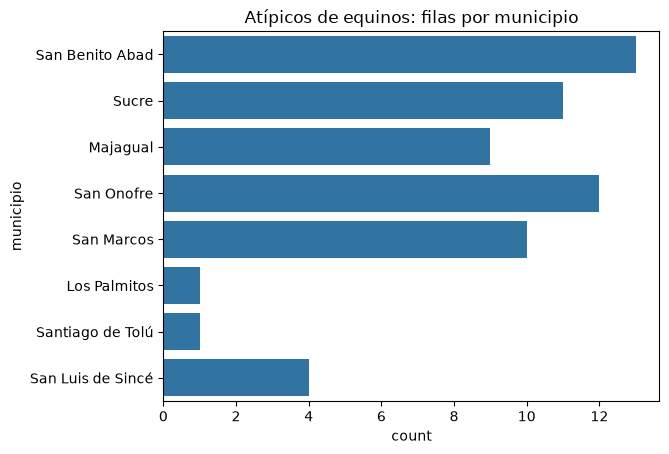

asnos atípicos altos: 28


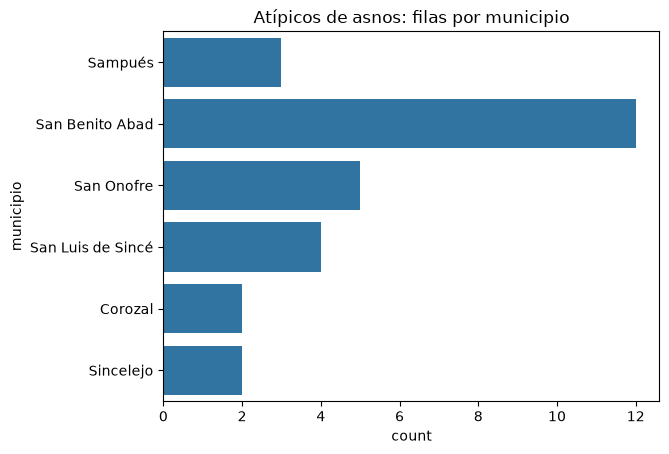

mulos atípicos altos: 41


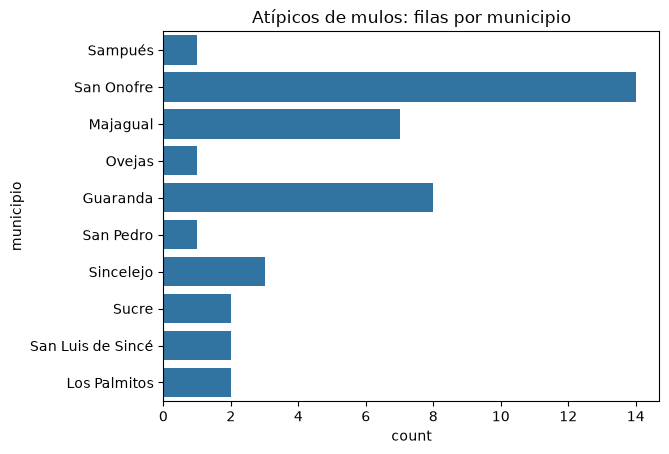

bufalos atípicos altos: 41


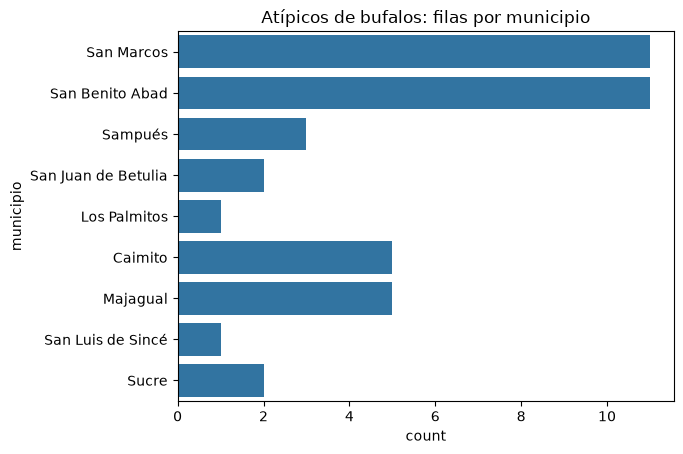

ovinos atípicos altos: 10


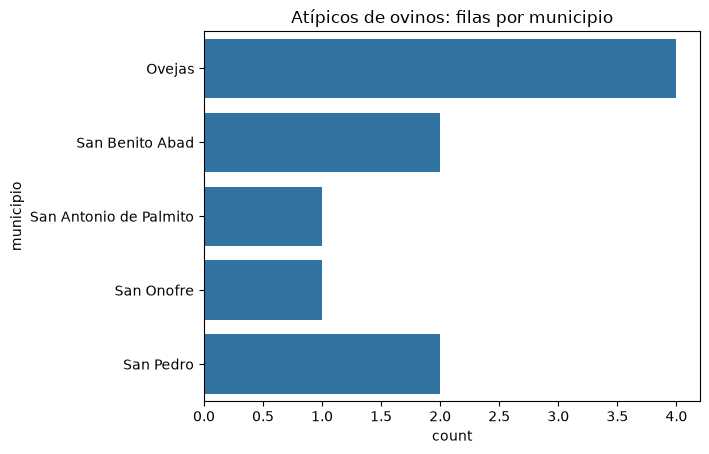

caprinos atípicos altos: 54


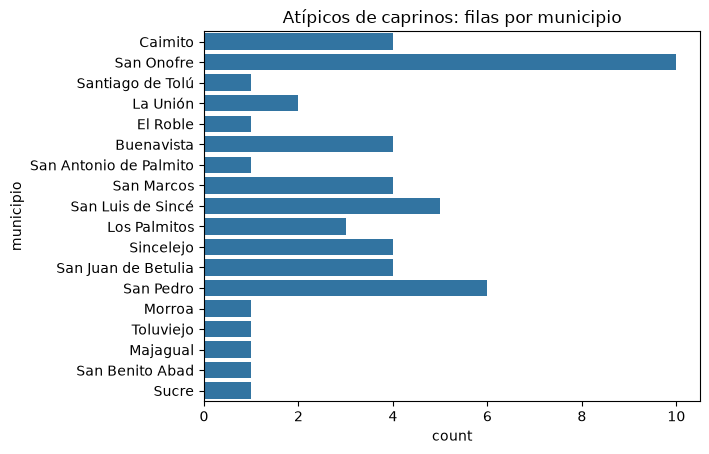

total atípicos altos: 46


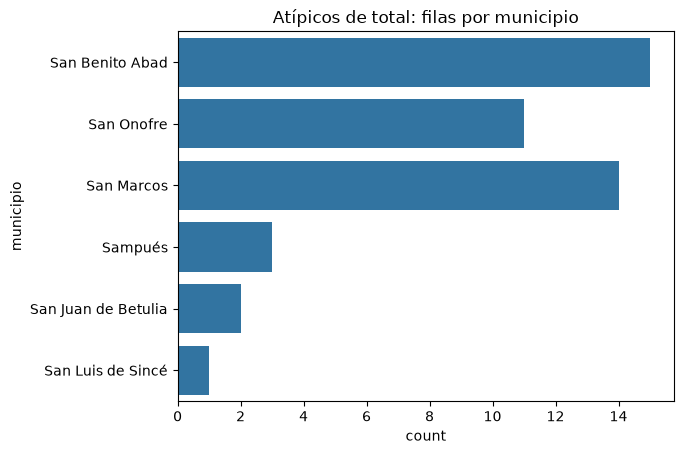

In [288]:
columnas_estadisticas = ['equinos', 'asnos', 'mulos', 'bufalos', 'ovinos', 'caprinos', 'total']

for col in columnas_estadisticas:
    datos = df_datos[df_datos[col] > 0]
    p25 = np.percentile(datos[col], 25)
    p75 = np.percentile(datos[col], 75)
    limite_superior = p75 + 1.5 * (p75 - p25)
    atipicos = datos[datos[col] > limite_superior]
    print(col, "atípicos altos:", len(atipicos))
    sns.countplot(data=atipicos, y='municipio')
    plt.title(f"Atípicos de {col}: filas por municipio")
    plt.show()

Los conteos de atípicos por municipio coinciden con los de la tabla (61, 28, 41, 41, 10, 54 y 46). En equinos, mulos, bufalos y total, los atípicos se concentran en pocos municipios: por ejemplo, cinco municipios reúnen 55 de los 61 atípicos de equinos, y tres reúnen 40 de los 46 de total. San Benito Abad y San Onofre aparecen en seis de los siete gráficos. En caprinos, en cambio, los atípicos están repartidos en 18 municipios.

Como cada municipio tiene como máximo 24 filas, que un municipio tenga 13 o más atípicos significa que supera el límite en más de la mitad de sus años. Un error de digitación aislado daría una sola fila, así que estos casos parecen inventarios grandes sostenidos y no errores. Sin embargo, la regla del IQR la calculé con todas las filas juntas, sin separar municipios, por lo que en la práctica señala a los municipios con más animales.

Decido conservar los atípicos, porque parecen valores reales y no errores, y eliminarlos descartaría a los municipios con los inventarios más grandes. No comprobé el valor de un mismo municipio a lo largo de los años, así que que sean reales es una interpretación y no un hecho comprobado. Lo tendré en cuenta en las comparaciones entre grupos, porque estos valores altos pueden influir mucho en los promedios.

Ahora, para comparar una variable numérica entre grupos, comparo el inventario de cada especie entre las cinco subregiones. Para cada especie y cada subregión calculo la mediana y los percentiles 25 y 75, usando solo las filas con valor mayor que 0 para excluir los ceros de relleno, y cuento cuántas filas se usaron (n). Uso la mediana porque conservé los atípicos, y la mediana se afecta menos por ellos que el promedio. Después hago un diagrama de cajas por especie, con una caja por subregión. No tengo una expectativa clara: quiero ver si el inventario de cada especie difiere entre subregiones.

In [289]:
columnas_especies = ['equinos', 'asnos', 'mulos', 'bufalos', 'ovinos', 'caprinos']

especie_lista = []
subregion_lista = []
n_lista = []
mediana_lista = []
p25_lista = []
p75_lista = []

for col in columnas_especies:
    for sub in subregiones_esperadas:
        filas_sub = df_datos[df_datos['subregion'] == sub]
        datos = filas_sub[filas_sub[col] > 0][col]
        especie_lista.append(col)
        subregion_lista.append(sub)
        n_lista.append(len(datos))
        mediana_lista.append(np.median(datos))
        p25_lista.append(np.percentile(datos, 25))
        p75_lista.append(np.percentile(datos, 75))

tabla_subregiones = pd.DataFrame({'especie': especie_lista,
                                  'subregion': subregion_lista,
                                  'n': n_lista,
                                  'mediana': mediana_lista,
                                  'p25': p25_lista,
                                  'p75': p75_lista})
tabla_subregiones

,especie,subregion,n,mediana,p25,p75
0,equinos,San Jorge,96,2308.0,1212.75,4312.50
1,equinos,Mojana,71,2700.0,2064.50,4474.00
2,equinos,Montes de María,120,660.0,307.25,1600.00
3,equinos,Sabanas,216,1586.5,1217.75,2048.25
4,equinos,Morrosquillo,117,1450.0,1114.00,2000.00
5,asnos,San Jorge,67,800.0,205.50,1242.00
6,asnos,Mojana,46,150.0,110.50,211.50
7,asnos,Montes de María,85,694.0,470.00,1100.00
8,asnos,Sabanas,150,463.5,301.25,974.00
9,asnos,Morrosquillo,83,800.0,360.00,1025.00


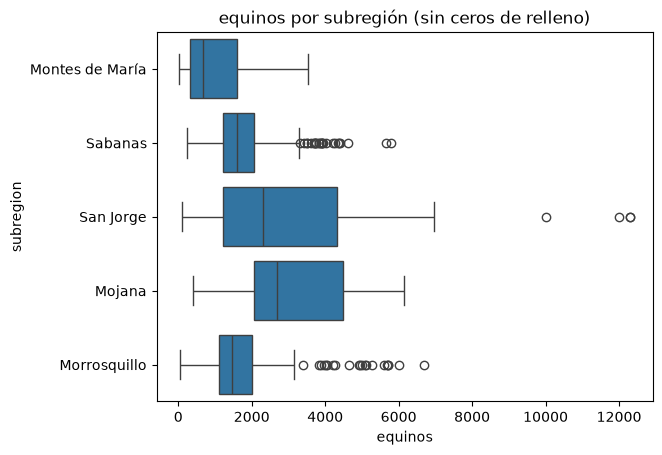

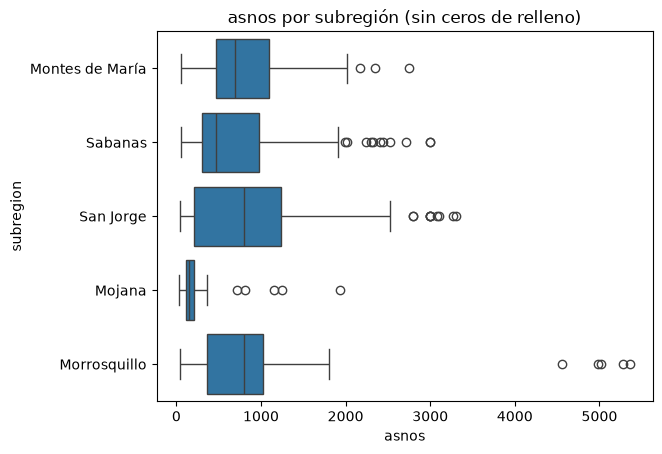

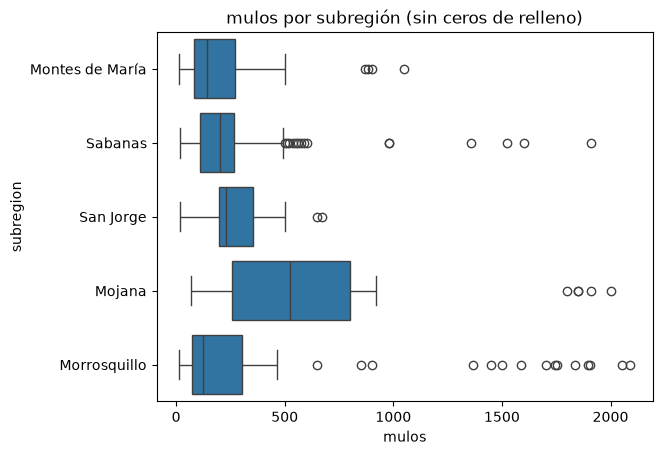

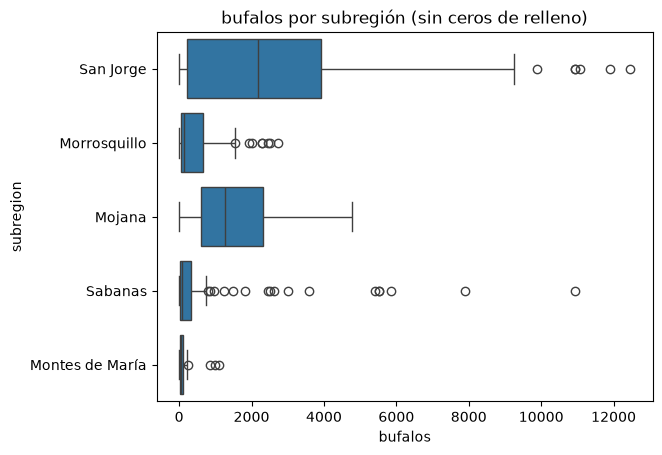

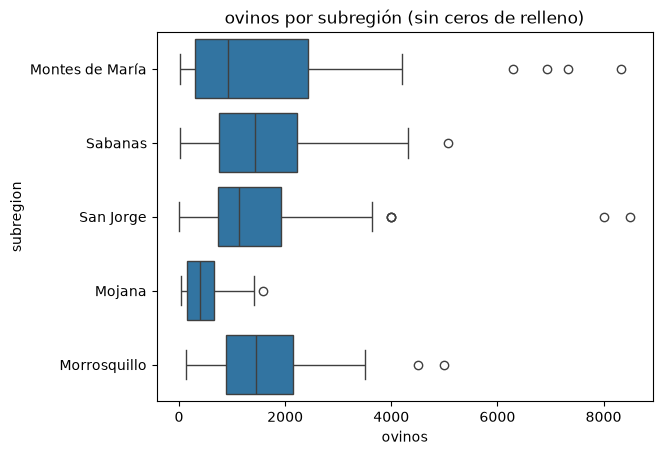

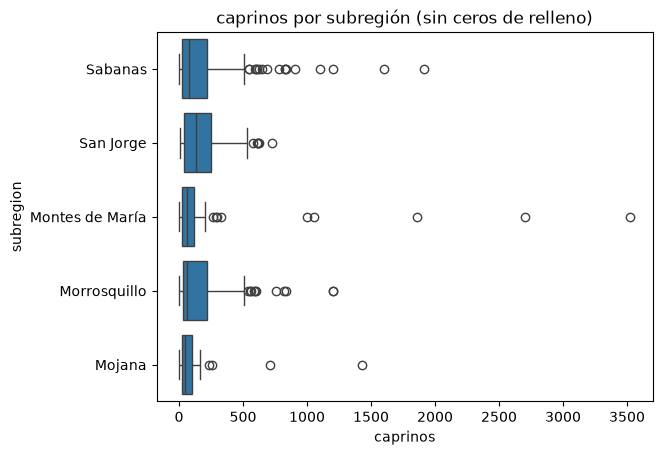

In [290]:
for col in columnas_especies:
    datos = df_datos[df_datos[col] > 0]
    sns.boxplot(data=datos, x=col, y='subregion')
    plt.title(f"{col} por subregión (sin ceros de relleno)")
    plt.show()

La tabla y los diagramas de cajas muestran que el inventario de cada especie difiere entre subregiones, y que el orden no es el mismo para todas las especies. Mojana tiene la mediana más alta en equinos (2700) y mulos (525), pero la más baja en asnos (150), ovinos (393,5) y caprinos (48). San Jorge tiene la mediana más alta en bufalos (2191), seguida por Mojana (1262), mientras que Montes de María (55), Sabanas (76) y Morrosquillo (139) tienen medianas mucho menores. En ovinos las medianas más altas son las de Morrosquillo (1456) y Sabanas (1434). En caprinos las medianas son bajas en las cinco subregiones, entre 48 y 134, y es la especie donde menos difieren: la mayor es unas 2,8 veces la menor, frente a unas 40 veces en bufalos.

En casi todas las subregiones hay valores atípicos altos, y varios están muy lejos de la caja. Por ejemplo, en equinos de San Jorge hay tres valores entre unos 10000 y 12300, frente a una mediana de 2308; en bufalos de San Jorge hay valores de hasta unos 12500; en asnos de Morrosquillo hay cinco valores entre unos 4500 y 5400, frente a una mediana de 800; y en caprinos de Montes de María hay uno de unos 3500, frente a una mediana de 62,5. Las excepciones, sin puntos fuera de los bigotes, son Montes de María y Mojana en equinos, y Mojana en bufalos.

Ahora, para ver si dos variables categóricas están asociadas, cruzo la subregión con una variable nueva de verdadero o falso: si el inventario de equinos de una fila supera el límite de atípicos de la regla de 1,5 × IQR. Para crearla uso la misma idea del profesor con "lower_outlier": una columna que sale de una comparación. Calculo el límite con las filas de equinos mayores que 0, para excluir los ceros de relleno, y en la tabla solo uso esas filas. Para cada subregión cuento cuántas filas son atípicas y cuántas no, y calculo el porcentaje de atípicas. Después lo muestro en un gráfico de conteo.

In [291]:
especie = 'equinos'

datos = df_datos[df_datos[especie] > 0]
p25 = np.percentile(datos[especie], 25)
p75 = np.percentile(datos[especie], 75)
limite_superior = p75 + 1.5 * (p75 - p25)

df_datos[f'atipico_{especie}'] = df_datos[especie] > limite_superior

subregion_lista = []
n_lista = []
atipicas_lista = []
no_atipicas_lista = []
porcentaje_lista = []

datos = df_datos[df_datos[especie] > 0]
for sub in subregiones_esperadas:
    filas_sub = datos[datos['subregion'] == sub]
    atipicas = len(filas_sub[filas_sub[f'atipico_{especie}'] == True])
    no_atipicas = len(filas_sub[filas_sub[f'atipico_{especie}'] == False])
    subregion_lista.append(sub)
    n_lista.append(len(filas_sub))
    atipicas_lista.append(atipicas)
    no_atipicas_lista.append(no_atipicas)
    porcentaje_lista.append(round(atipicas / len(filas_sub) * 100, 1))

tabla_asociacion = pd.DataFrame({'subregion': subregion_lista,
                                 'n': n_lista,
                                 'atipicas': atipicas_lista,
                                 'no_atipicas': no_atipicas_lista,
                                 'porcentaje_atipicas': porcentaje_lista})
tabla_asociacion

,subregion,n,atipicas,no_atipicas,porcentaje_atipicas
0,San Jorge,96,23,73,24.0
1,Mojana,71,20,51,28.2
2,Montes de María,120,0,120,0.0
3,Sabanas,216,5,211,2.3
4,Morrosquillo,117,13,104,11.1


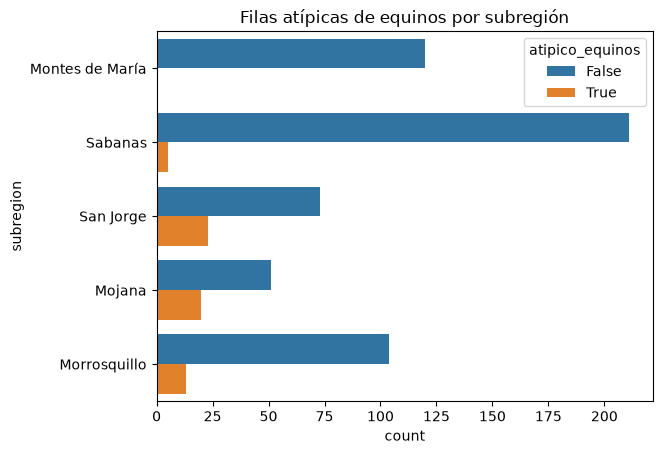

In [292]:
sns.countplot(data=datos, y='subregion', hue=f'atipico_{especie}')
plt.title(f"Filas atípicas de {especie} por subregión")
plt.show()

La tabla muestra que ser atípico en equinos depende de la subregión: el porcentaje de filas atípicas es 0 % en Montes de María, 2,3 % en Sabanas, 11,1 % en Morrosquillo, 24,0 % en San Jorge y 28,2 % en Mojana, frente a 9,8 % en todo el conjunto (61 de 620). San Jorge y Mojana reúnen 43 de las 61 filas atípicas (70 %) con 167 de las 620 filas (27 %). Esto indica que la subregión y ser atípico están asociados. Las 61 filas coinciden con la tabla de estadísticos.

Con la columna nueva atipico_equinos, el conjunto queda con 621 filas y 11 columnas.

Para ver si las especies se relacionan entre sí, calculo la correlación entre cada par de especies (15 pares). Para cada par uso solo las filas donde las dos especies son mayores que 0, para excluir los ceros de relleno, y guardo cuántas filas se usaron (n), porque cambia mucho según el par. Para calcular la correlación uso `.corr()`, que no vimos en clase y declaro como sugerido por la IA. No incluyo total porque es la suma de las especies y estaría correlacionado con todas por construcción. Conservé los valores atípicos, y la correlación se afecta por los valores muy grandes, así que puede depender de unos pocos municipios con inventarios altos. No tengo una expectativa clara de qué pares estarán más relacionados. No hago una prueba de significancia: solo describo el valor de la correlación.

In [293]:
pares = [['equinos', 'asnos'], ['equinos', 'mulos'], ['equinos', 'bufalos'], ['equinos', 'ovinos'], ['equinos', 'caprinos'],
         ['asnos', 'mulos'], ['asnos', 'bufalos'], ['asnos', 'ovinos'], ['asnos', 'caprinos'],
         ['mulos', 'bufalos'], ['mulos', 'ovinos'], ['mulos', 'caprinos'],
         ['bufalos', 'ovinos'], ['bufalos', 'caprinos'],
         ['ovinos', 'caprinos']]

especie_a_lista = []
especie_b_lista = []
n_lista = []
correlacion_lista = []

for par in pares:
    a = par[0]
    b = par[1]
    filas = df_datos[df_datos[a] > 0]
    filas = filas[filas[b] > 0]

    correlacion = filas[a].corr(filas[b])

    especie_a_lista.append(a)
    especie_b_lista.append(b)
    n_lista.append(len(filas))
    correlacion_lista.append(round(correlacion, 2))

tabla_correlaciones = pd.DataFrame({'especie_a': especie_a_lista,
                                    'especie_b': especie_b_lista,
                                    'n': n_lista,
                                    'correlacion': correlacion_lista})
tabla_correlaciones

,especie_a,especie_b,n,correlacion
0,equinos,asnos,431,0.42
1,equinos,mulos,434,0.43
2,equinos,bufalos,376,0.29
3,equinos,ovinos,607,0.38
4,equinos,caprinos,441,0.04
5,asnos,mulos,431,0.29
6,asnos,bufalos,240,0.15
7,asnos,ovinos,423,0.33
8,asnos,caprinos,282,0.21
9,mulos,bufalos,242,0.05


Todas las correlaciones son débiles o moderadas: van de −0,17 (bufalos con ovinos) a 0,43 (equinos con mulos). Las más altas son equinos con mulos (0,43, n = 434), equinos con asnos (0,42, n = 431), equinos con ovinos (0,38, n = 607) y asnos con ovinos (0,33). Las más cercanas a cero son equinos con caprinos (0,04) y mulos con bufalos (0,05). Trece de los quince pares tienen correlación positiva; las dos negativas son de bufalos, con ovinos (−0,17) y con caprinos (−0,12). El número de filas usadas cambia entre pares, desde 240 (asnos con bufalos) hasta 607 (equinos con ovinos).

Estas correlaciones mezclan 26 municipios y 24 años, y se calcularon con los valores atípicos incluidos, así que pueden depender de unos pocos municipios con inventarios grandes. Además, miden solo la relación lineal y no indican causalidad.

Ahora hago las cinco figuras del análisis: una de distribución, una de comparación entre grupos, una de relación entre dos variables numéricas, una de evolución en el tiempo y un mapa de calor. Después, con estas figuras y las tablas anteriores, respondo tres preguntas.

**Figura 1: distribución.** 
Objetivo: ver cómo se distribuye el inventario de ovinos. Uso un histograma porque muestra la forma de la distribución, es decir, si es simétrica o tiene cola y dónde se concentran los valores. Marco con líneas el percentil 25 (verde), la mediana (rojo) y el percentil 75 (negro), como se hizo en clase. Elegí ovinos porque casi todas las filas tienen dato (607 de 621) y excluyo los ceros de relleno. Un diagrama de cajas habría resumido lo mismo en cinco números, pero habría ocultado la forma de la distribución, por ejemplo si hay más de una concentración de valores.

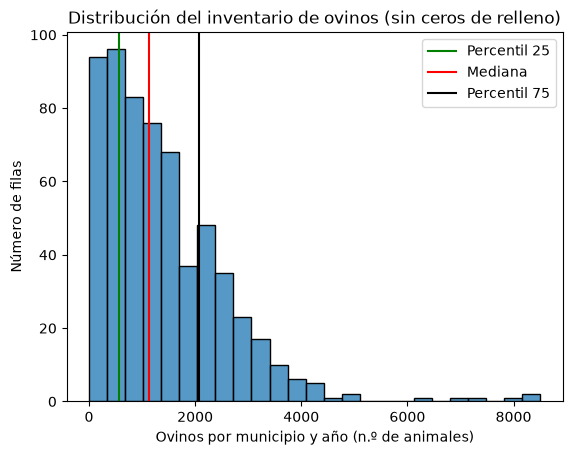

In [294]:
datos = df_datos[df_datos['ovinos'] > 0]['ovinos']
mediana = np.median(datos)
p25 = np.percentile(datos, 25)
p75 = np.percentile(datos, 75)

sns.histplot(datos)

plt.axvline(p25, color='green', label='Percentil 25')
plt.axvline(mediana, color='red', label='Mediana')
plt.axvline(p75, color='black', label='Percentil 75')
plt.legend()
plt.title("Distribución del inventario de ovinos (sin ceros de relleno)")

plt.xlabel("Ovinos por municipio y año (n.º de animales)")
plt.ylabel("Número de filas")
plt.show()

**Leyenda.** La mayoría de las filas tiene pocos ovinos: la mediana es 1137 animales y la mitad central de los datos va de 575 a 2068. La distribución es asimétrica, con una cola larga hacia valores altos. Más allá de unos 4300 animales, el límite de atípicos, hay solo 10 filas, algunas aisladas cerca de 6200 y 8500. Línea verde: percentil 25; roja: mediana; negra: percentil 75. Se excluyen los ceros de relleno (n = 607).

**Figura 2: comparación entre grupos.** 
Objetivo: ver si el inventario de búfalos difiere entre subregiones. Uso un diagrama de cajas porque permite comparar las cinco subregiones a la vez: cada caja muestra la mediana, la mitad central de los datos y los valores atípicos. Elegí búfalos porque es la especie en la que las medianas más difieren entre subregiones (de 55 en Montes de María a 2191 en San Jorge, según la tabla anterior). Excluyo los ceros de relleno. Un gráfico de violín mostraría la forma completa de cada distribución, pero con colas tan largas podría verse aplastado y ser más difícil de leer. Un gráfico de barras con el promedio ocultaría la dispersión y los atípicos, y el promedio se afectaría mucho por esos valores.

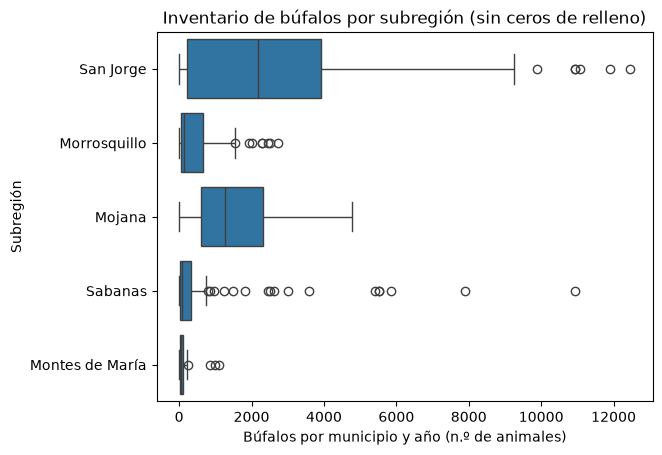

In [295]:
datos = df_datos[df_datos['bufalos'] > 0]

sns.boxplot(data=datos, x='bufalos', y='subregion')
plt.title("Inventario de búfalos por subregión (sin ceros de relleno)")

plt.xlabel("Búfalos por municipio y año (n.º de animales)")
plt.ylabel("Subregión")
plt.show()

**Leyenda.** El inventario de búfalos difiere mucho entre subregiones. San Jorge tiene la mediana más alta (2191 animales) y la mayor dispersión, con valores de hasta unos 12500. Mojana le sigue (1262). Morrosquillo, Sabanas y Montes de María tienen medianas bajas (139, 76 y 55) y sus cajas se ven aplastadas por la escala. Se excluyen los ceros de relleno (n = 376).

**Figura 3: relación entre dos variables numéricas.** 
Objetivo: ver si los municipios con más equinos tienen también más mulos. Uso un diagrama de dispersión porque cada punto es una fila (un municipio en un año), y así se ve si los dos inventarios suben juntos, dónde se concentran los puntos y si hay valores muy alejados. Elegí equinos y mulos porque es el par con la correlación más alta de la tabla anterior (0,43, con 434 filas). Uso solo las filas donde las dos especies son mayores que 0, para excluir los ceros de relleno, y coloreo cada punto por subregión para ver si los grupos se separan. Hago los puntos semitransparentes porque muchos se superponen. La correlación orienta, pero solo mide relación lineal y no capta relaciones curvas. Una tabla de correlaciones habría dado solo un número y habría ocultado la forma de la nube de puntos y los valores extremos.

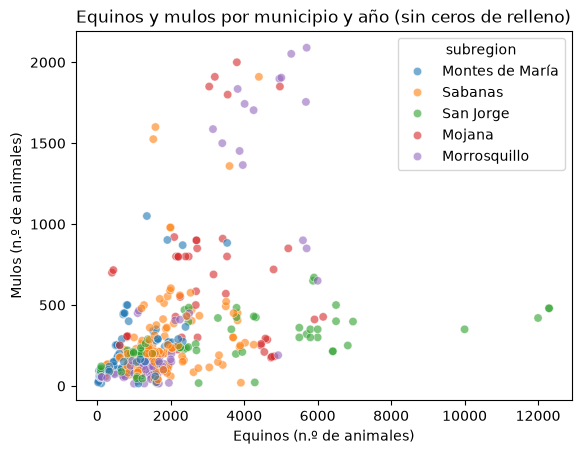

In [296]:
datos = df_datos[df_datos['equinos'] > 0]
datos = datos[datos['mulos'] > 0]

sns.scatterplot(data=datos, x='equinos', y='mulos', hue='subregion', alpha=0.6)

plt.title("Equinos y mulos por municipio y año (sin ceros de relleno)")

plt.xlabel("Equinos (n.º de animales)")
plt.ylabel("Mulos (n.º de animales)")
plt.show()

**Leyenda.** Cada punto es un municipio en un año (n = 434). Equinos y mulos tienden a subir juntos, pero la relación es débil (correlación 0,43): la mayoría de los puntos se amontona por debajo de unos 3000 equinos y 500 mulos. Los valores extremos van en dos direcciones: San Jorge llega a unos 12300 equinos con pocos mulos, y Morrosquillo y Mojana alcanzan unos 2000 mulos con 3000 a 6000 equinos. Se excluyen los ceros de relleno.

**Figura 4: evolución en el tiempo.** 
Objetivo: ver cómo cambió el inventario de equinos entre 2001 y 2025 y si cambia igual en las cinco subregiones. Uso un gráfico de líneas porque el tiempo es continuo y la línea muestra la tendencia; una línea por subregión permite compararlas. Cada línea es el promedio por municipio de cada año, y la banda sombreada es la incertidumbre que calcula seaborn (intervalo de confianza del 95 %). Excluyo los ceros de relleno. Un gráfico de barras habría necesitado 24 barras por subregión y habría ocultado la tendencia. Hay que tener en cuenta que en 2001, 2002 y 2024 el promedio de Morrosquillo se calcula sin Coveñas o sin Santiago de Tolú (registros que faltan), y que Mojana en 2010 no tiene el dato de Sucre; la línea une esos puntos sin avisar el hueco.

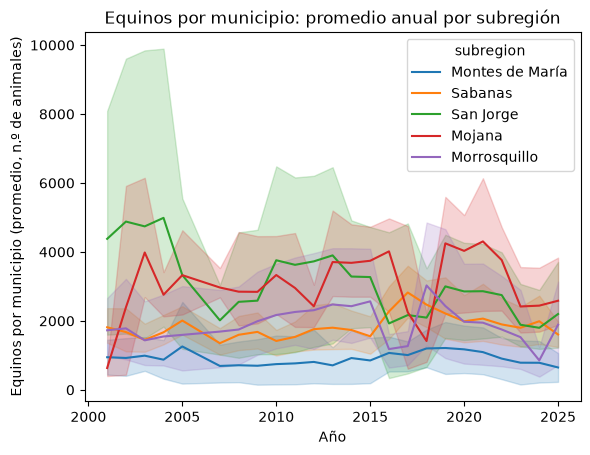

In [297]:
datos = df_datos[df_datos['equinos'] > 0]

sns.lineplot(data=datos, x='año', y='equinos', hue='subregion')

plt.title("Equinos por municipio: promedio anual por subregión")

plt.xlabel("Año")
plt.ylabel("Equinos por municipio (promedio, n.º de animales)")
plt.show()

**Leyenda.** Cada línea es el promedio de equinos por municipio en una subregión; la banda es el intervalo de confianza del 95 %. Montes de María es la más baja y estable, entre unos 700 y 1200. San Jorge parte más alto, de 4400 a 5000 hasta 2004, y termina cerca de 2200 en 2025. Mojana es la más variable: unos 600 en 2001 y un salto a unos 4200 en 2019. Las bandas de ambas son muy anchas.

**Figura 5: matriz de correlaciones.** 
Objetivo: ver de un vistazo qué pares de especies se relacionan más. Uso un mapa de calor porque muestra los 15 pares a la vez en una sola imagen, y el color permite ubicar rápido los pares más altos y los negativos. Como las correlaciones tienen signo, uso una paleta divergente (azul para negativas, rojo para positivas) centrada en 0, con una escala fija de −1 a 1, y escribo el valor dentro de cada celda. Cada par usa solo las filas donde las dos especies son mayores que 0. Una tabla de 15 filas habría dado los mismos números, pero habría sido más difícil ver cuáles son altos y cuáles bajos. Un mapa de calor puede ocultar el n de cada par, que cambia entre 240 y 607 filas.

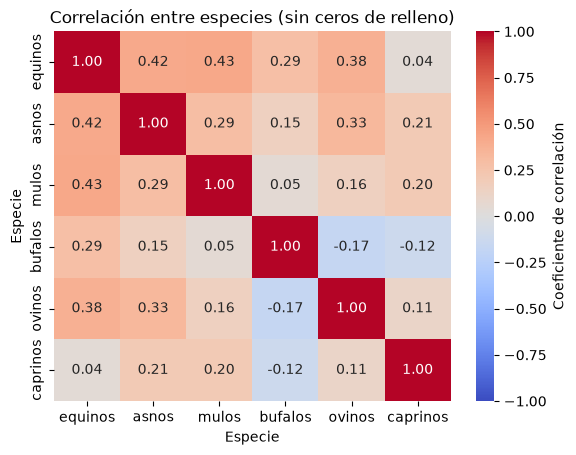

In [298]:
columnas_especies = ['equinos', 'asnos', 'mulos', 'bufalos', 'ovinos', 'caprinos']

matriz = {}
for a in columnas_especies:
    valores = []
    for b in columnas_especies:
        filas = df_datos[df_datos[a] > 0]
        filas = filas[filas[b] > 0]
        # sugerido por IA (no visto en clase): .corr() calcula la correlación entre dos columnas
        valores.append(filas[a].corr(filas[b]))
    matriz[a] = valores

tabla_matriz = pd.DataFrame(matriz, index=columnas_especies)

sns.heatmap(tabla_matriz, annot=True, fmt='.2f', cmap='coolwarm', vmin=-1, vmax=1,
            cbar_kws={'label': 'Coeficiente de correlación'})

plt.title("Correlación entre especies (sin ceros de relleno)")

plt.xlabel("Especie")
plt.ylabel("Especie")
plt.show()

**Leyenda.** Las correlaciones entre especies son débiles a moderadas, de −0,17 a 0,43. Las más altas son equinos con mulos (0,43), equinos con asnos (0,42) y equinos con ovinos (0,38). Las más cercanas a cero son equinos con caprinos (0,04) y mulos con búfalos (0,05). Solo búfalos tiene correlaciones negativas, con ovinos (−0,17) y caprinos (−0,12). Cada par usa solo las filas donde ambas especies son mayores que 0. Escala de color: azul-rojo, centrada en 0.

**Pregunta 1: ¿el inventario de las especies difiere entre subregiones?**

Sí, y la diferencia depende de la especie. En búfalos, la mediana va de 55 en Montes de María a 2191 en San Jorge, unas 40 veces más. Mojana tiene la mediana más alta en equinos (2700) y mulos (525), y la más baja en asnos (150), ovinos (393,5) y caprinos (48). Caprinos es la especie donde menos difieren las subregiones: sus medianas van de 48 a 134. Además, ser atípico en equinos depende de la subregión: es 0 % en Montes de María, 2,3 % en Sabanas, 11,1 % en Morrosquillo, 24,0 % en San Jorge y 28,2 % en Mojana. San Jorge y Mojana reúnen 43 de las 61 filas atípicas (70 %) con el 27 % de las filas.

Respaldo: Figura 2, tabla por subregión (`tabla_subregiones`) y tabla de asociación entre subregión y atípicos en equinos (`tabla_asociacion`).

**Pregunta 2: ¿cómo cambió el inventario de equinos entre 2001 y 2025, y cambió igual en todas las subregiones?**
No hay una tendencia común: las cinco subregiones no cambian igual. Montes de María es la más baja y estable, entre unos 700 y 1200 equinos por municipio. Sabanas se mantiene entre unos 1400 y 2000, con un máximo de unos 2800 hacia 2017. San Jorge tiene el descenso más marcado: de 4400 a 5000 hasta 2004 a cerca de 2200 en 2025. Mojana es la más variable: parte de unos 600 en 2001, sube a unos 4000 hacia 2016, cae a unos 1400 en 2018 y salta a unos 4200 en 2019. Morrosquillo oscila entre unos 900 y 3000. Las bandas de San Jorge y Mojana son muy anchas, así que sus promedios son poco precisos.

Respaldo: Figura 4.

**Pregunta 3: ¿las especies se relacionan entre sí?**
Solo de forma débil o moderada. Las correlaciones van de −0,17 a 0,43. Las más altas son equinos con mulos (0,43), equinos con asnos (0,42) y equinos con ovinos (0,38); las más cercanas a cero, equinos con caprinos (0,04) y mulos con búfalos (0,05). Trece de los quince pares son positivos, y los dos negativos son de búfalos (con ovinos, −0,17, y con caprinos, −0,12). En el diagrama de dispersión de equinos y mulos, la mayoría de los puntos se amontona con pocos animales, y los valores extremos van en direcciones distintas: San Jorge tiene muchos equinos y pocos mulos, y Morrosquillo y Mojana tienen muchos mulos con equinos intermedios.

Respaldo: Figura 3, Figura 5 y tabla de correlaciones (`tabla_correlaciones`).

**Limitaciones del análisis**

**Cómo se recogieron los datos y a quién representan.** El conjunto lo publica la Gobernación de Sucre y cubre los 26 municipios del departamento, de 2001 a 2025, sin 2006. En la ficha del conjunto no encontré cómo se recogieron los datos (si es un censo, una encuesta o un reporte de cada municipio), así que no sé qué tan confiables son las cifras. Los resultados representan solo al departamento de Sucre y solo a las seis especies del conjunto, no a todo el inventario pecuario ni a otros departamentos. Cada fila es un municipio en un año, no una finca ni un productor.

**Efecto de los faltantes.** Asnos, mulos, búfalos y caprinos tienen entre 29 % y 40 % de sus filas vacías (por ejemplo, 245 de 621 en búfalos). Esos vacíos los llené con 0 y los excluí al calcular, así que las medianas, las comparaciones y las correlaciones de esas especies se apoyan solo en las filas con dato. Por eso el número de filas cambia según la especie y el par (de 240 a 607 en las correlaciones). No sé si un vacío significa que no se registró el dato o que no había animales. Si fuera lo segundo, mis cifras de esas especies estarían sobrestimadas: en búfalos de Montes de María, por ejemplo, la mediana se calculó con 39 de sus 120 filas. Además, no existen 3 de los 624 registros esperados (Coveñas en 2001 y 2002, y Santiago de Tolú en 2024), hay una fila de Sucre en 2010 sin ningún dato, y el año 2006 no aparece. En las líneas de la evolución en el tiempo, esos huecos se unen sin avisar.

**Efecto de las decisiones de limpieza.** Conservé los valores atípicos, porque no vi indicios de error, pero influyen en las correlaciones y en las comparaciones. La regla del IQR la calculé con todas las filas juntas, así que marca sobre todo a los municipios con inventarios grandes (San Benito Abad, San Marcos, San Onofre), y no comprobé el valor de un mismo municipio a lo largo de los años. Además, las filas de un mismo municipio en distintos años no son independientes entre sí, y todas las cifras mezclan municipios y años. No hice pruebas estadísticas: solo comparo medianas, porcentajes y correlaciones.

**Asociación y causalidad.** Lo que encontré son asociaciones, no causas. Que Mojana y San Jorge reúnan el 70 % de los atípicos de equinos, o que equinos y mulos tengan una correlación de 0,43, no muestra que la subregión o una especie cause algo en la otra. Esas diferencias pueden venir de factores que el conjunto no tiene, como el tamaño de cada municipio, cómo se registra el inventario o la actividad económica de cada zona. Además, las correlaciones solo miden relación lineal.

**Qué haría falta para sostener estas conclusiones**

- **Saber qué significa un vacío.** La metodología del inventario, o una consulta a la Gobernación de Sucre, diría si un vacío es un dato no registrado o una especie ausente. De eso depende la mayoría de lo que concluyo sobre asnos, mulos, búfalos y caprinos.
- **Datos que permitan comparar municipios de distinto tamaño,** como su superficie o su población, para saber si las diferencias entre subregiones vienen de los inventarios o del tamaño de cada municipio.
- **Los registros que faltan** (2006, Coveñas en 2001 y 2002, y Santiago de Tolú en 2024) y la historia de un mismo municipio a lo largo de los años, para confirmar que los atípicos son valores reales y no errores.
- **Un análisis que separe el efecto del municipio del de la subregión y el año,** y una prueba estadística de las diferencias, porque aquí solo las describo.